In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/WA_Fn-UseC_-HR-Employee-Attrition.csv")  # use your actual file name
print(df.shape)
df.info()
df.head()

(1470, 35)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel     

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [3]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

# Columns with only one unique value carry no information
print(df.nunique().sort_values().head(8))

Missing values: 0
Duplicate rows: 0
EmployeeCount        1
Over18               1
StandardHours        1
Attrition            2
OverTime             2
PerformanceRating    2
Gender               2
BusinessTravel       3
dtype: int64


In [4]:
# Drop constant columns and the ID column (check the nunique output first)
df = df.drop(columns=["EmployeeCount", "Over18", "StandardHours", "EmployeeNumber"])

# Numeric flag for calculations
df["AttritionFlag"] = (df["Attrition"] == "Yes").astype(int)

df.to_csv("../data/hr_attrition_clean.csv", index=False)

Overall attrition rate: 16.1 %
                        count  mean
Department                         
Human Resources            63  19.0
Research & Development    961  13.8
Sales                     446  20.6


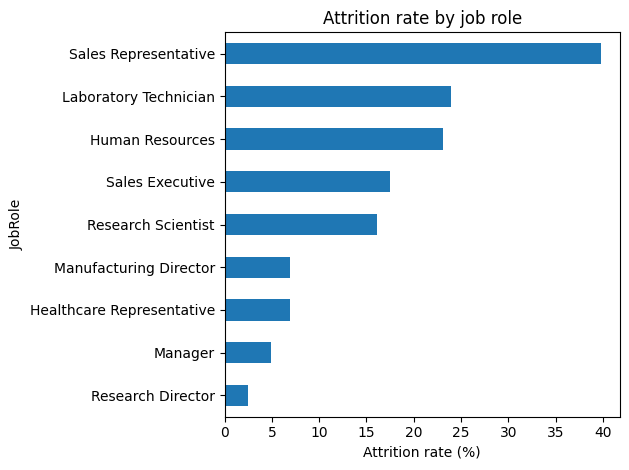

In [5]:
print("Overall attrition rate:", round(df["AttritionFlag"].mean() * 100, 1), "%")

by_dept = df.groupby("Department")["AttritionFlag"].agg(["count", "mean"])
by_dept["mean"] = (by_dept["mean"] * 100).round(1)
print(by_dept)

df.groupby("JobRole")["AttritionFlag"].mean().sort_values().mul(100).round(1).plot(kind="barh")
plt.xlabel("Attrition rate (%)")
plt.title("Attrition rate by job role")
plt.tight_layout()
plt.show()

          count  mean
OverTime             
No         1054  10.4
Yes         416  30.5


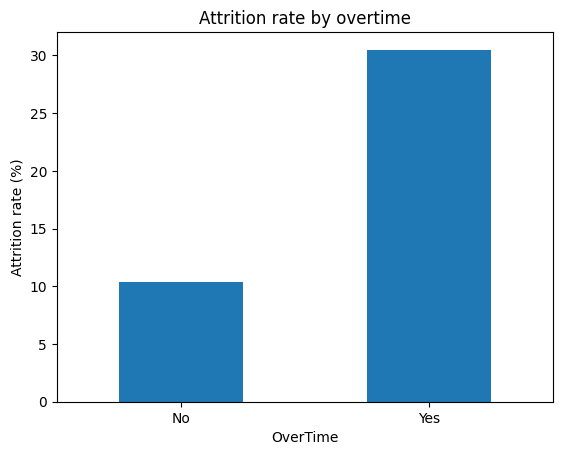

In [6]:
ot = df.groupby("OverTime")["AttritionFlag"].agg(["count", "mean"])
ot["mean"] = (ot["mean"] * 100).round(1)
print(ot)

ot["mean"].plot(kind="bar", rot=0)
plt.ylabel("Attrition rate (%)")
plt.title("Attrition rate by overtime")
plt.show()

IncomeBand
Lowest 25%     29.3
Low-mid        14.2
Mid-high       10.6
Highest 25%    10.3
Name: AttritionFlag, dtype: float64


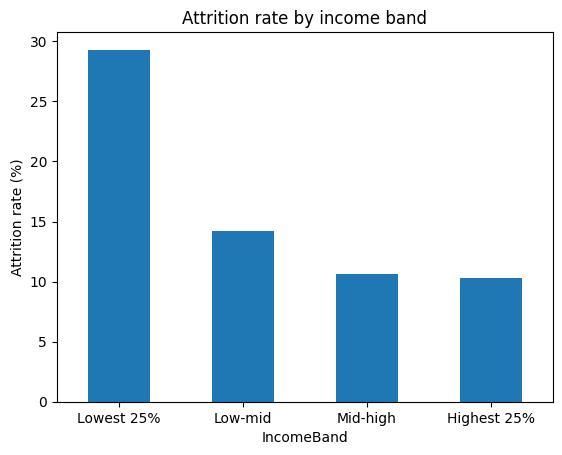

In [7]:
df["IncomeBand"] = pd.qcut(df["MonthlyIncome"], 4, labels=["Lowest 25%", "Low-mid", "Mid-high", "Highest 25%"])
inc = df.groupby("IncomeBand", observed=True)["AttritionFlag"].mean().mul(100).round(1)
print(inc)

inc.plot(kind="bar", rot=0)
plt.ylabel("Attrition rate (%)")
plt.title("Attrition rate by income band")
plt.show()

In [8]:
df["TenureBand"] = pd.cut(df["YearsAtCompany"], [-1, 2, 5, 10, 40], labels=["0-2 yrs", "3-5 yrs", "6-10 yrs", "10+ yrs"])
print(df.groupby("TenureBand", observed=True)["AttritionFlag"].mean().mul(100).round(1))

df["PromoBand"] = pd.cut(df["YearsSinceLastPromotion"], [-1, 1, 3, 7, 20], labels=["0-1 yrs", "2-3 yrs", "4-7 yrs", "8+ yrs"])
print(df.groupby("PromoBand", observed=True)["AttritionFlag"].mean().mul(100).round(1))

TenureBand
0-2 yrs     29.8
3-5 yrs     13.8
6-10 yrs    12.3
10+ yrs      8.1
Name: AttritionFlag, dtype: float64
PromoBand
0-1 yrs    17.0
2-3 yrs    17.1
4-7 yrs    13.6
8+ yrs     12.1
Name: AttritionFlag, dtype: float64
